# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

## Preprocessing

In [3]:
# some helper functions and classes (no need to check them now)
import sys
from pathlib import Path

# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

In [4]:

outcome_space = part1.clslib.NamedClasses(['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])
print(outcome_space)

0: sadness, 1: joy, 2: love, 3: anger, 4: fear, 5: surprise


In [5]:
from datasets import load_dataset, concatenate_datasets

#Loading our training corpus
# dataset = load_dataset("stanfordnlp/sst2")
dataset = load_dataset("dair-ai/emotion", "split")

### Merge Validation set with Training set.

In [6]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [7]:
dataset["train"] = concatenate_datasets([dataset['train'], dataset['validation']])
print(dataset)
del dataset["validation"]
print(dataset)


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 18000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 18000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [8]:
#An example of an article from our training corpus
print("---- Negative Example ----")
print("Text:", dataset["train"]["text"][0])
print("Gold label (id):", dataset["train"]["label"][0])
print("Gold label (name):", outcome_space.name(dataset["train"]["label"][0]))

print("---- Positive Example ----")
#An example of an article from our training corpus
print("Text:", dataset["train"]["text"][2])
print("Gold label (id):", dataset["train"]["label"][2])
print("Gold label (name):", outcome_space.name(dataset["train"]["label"][2]))


---- Negative Example ----
Text: i didnt feel humiliated
Gold label (id): 0
Gold label (name): sadness
---- Positive Example ----
Text: im grabbing a minute to post i feel greedy wrong
Gold label (id): 3
Gold label (name): anger


---- train Set ----
Total examples: 18000
Sadness: 5216 examples (28.98%)
Joy: 6066 examples (33.70%)
Love: 1482 examples (8.23%)
Anger: 2434 examples (13.52%)
Fear: 2149 examples (11.94%)
Surprise: 653 examples (3.63%)


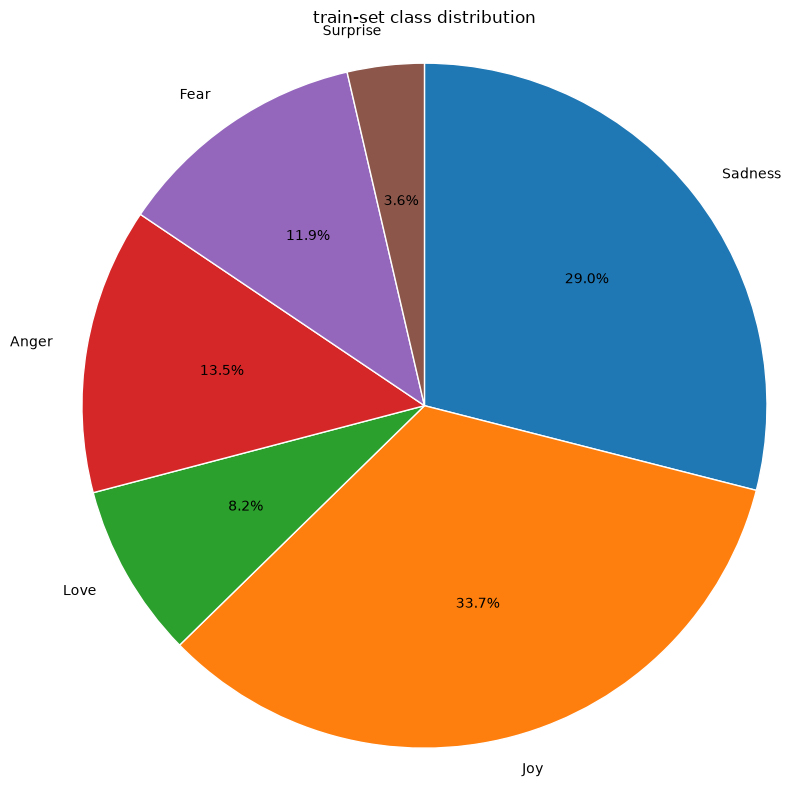

---- test Set ----
Total examples: 2000
Sadness: 581 examples (29.05%)
Joy: 695 examples (34.75%)
Love: 159 examples (7.95%)
Anger: 275 examples (13.75%)
Fear: 224 examples (11.20%)
Surprise: 66 examples (3.30%)


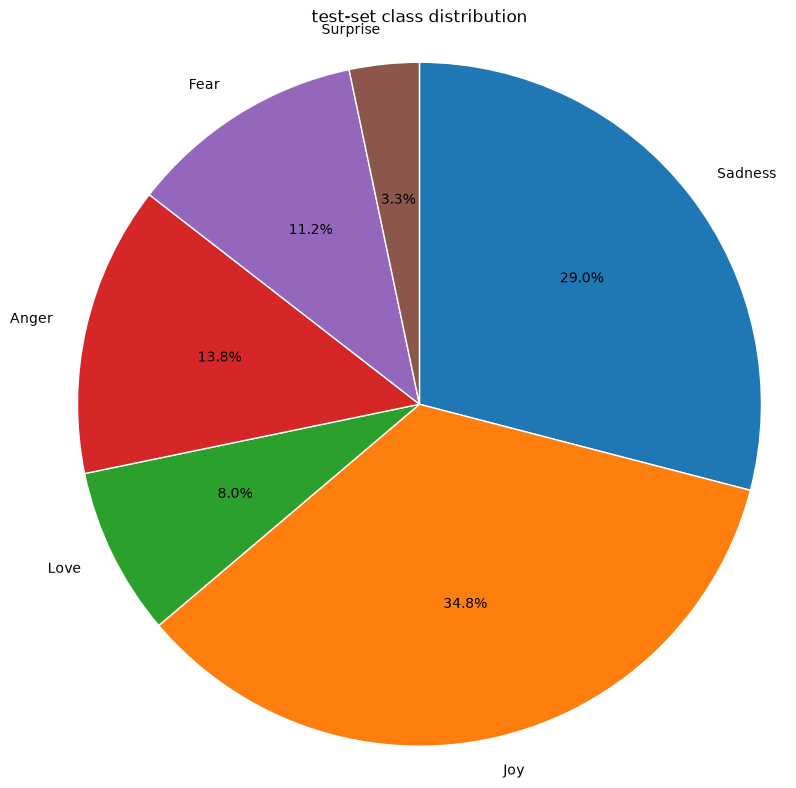

In [9]:
import matplotlib.pyplot as plt
import numpy as np
for set in ['train', 'test']:
    labels = np.array(dataset[set]["label"])
    class_names = outcome_space.names
    num_classes = len(class_names)

    class_counts = np.bincount(labels, minlength=num_classes)
    class_percentages = class_counts / labels.size * 100

    print(f"---- {set} Set ----")
    print(f"Total examples: {labels.size}")

    for label_id, label_name in enumerate(class_names):
        print(
            f"{label_name.title()}: "
            f"{class_counts[label_id]} examples "
            f"({class_percentages[label_id]:.2f}%)"
        )

    fig, ax = plt.subplots(figsize=(8, 8))

    ax.pie(
        class_counts,
        labels=[name.title() for name in class_names],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1,
        },
    )

    ax.set_title(f"{set}-set class distribution")
    ax.axis("equal")  # Keep the pie circular

    plt.tight_layout()
    plt.show()

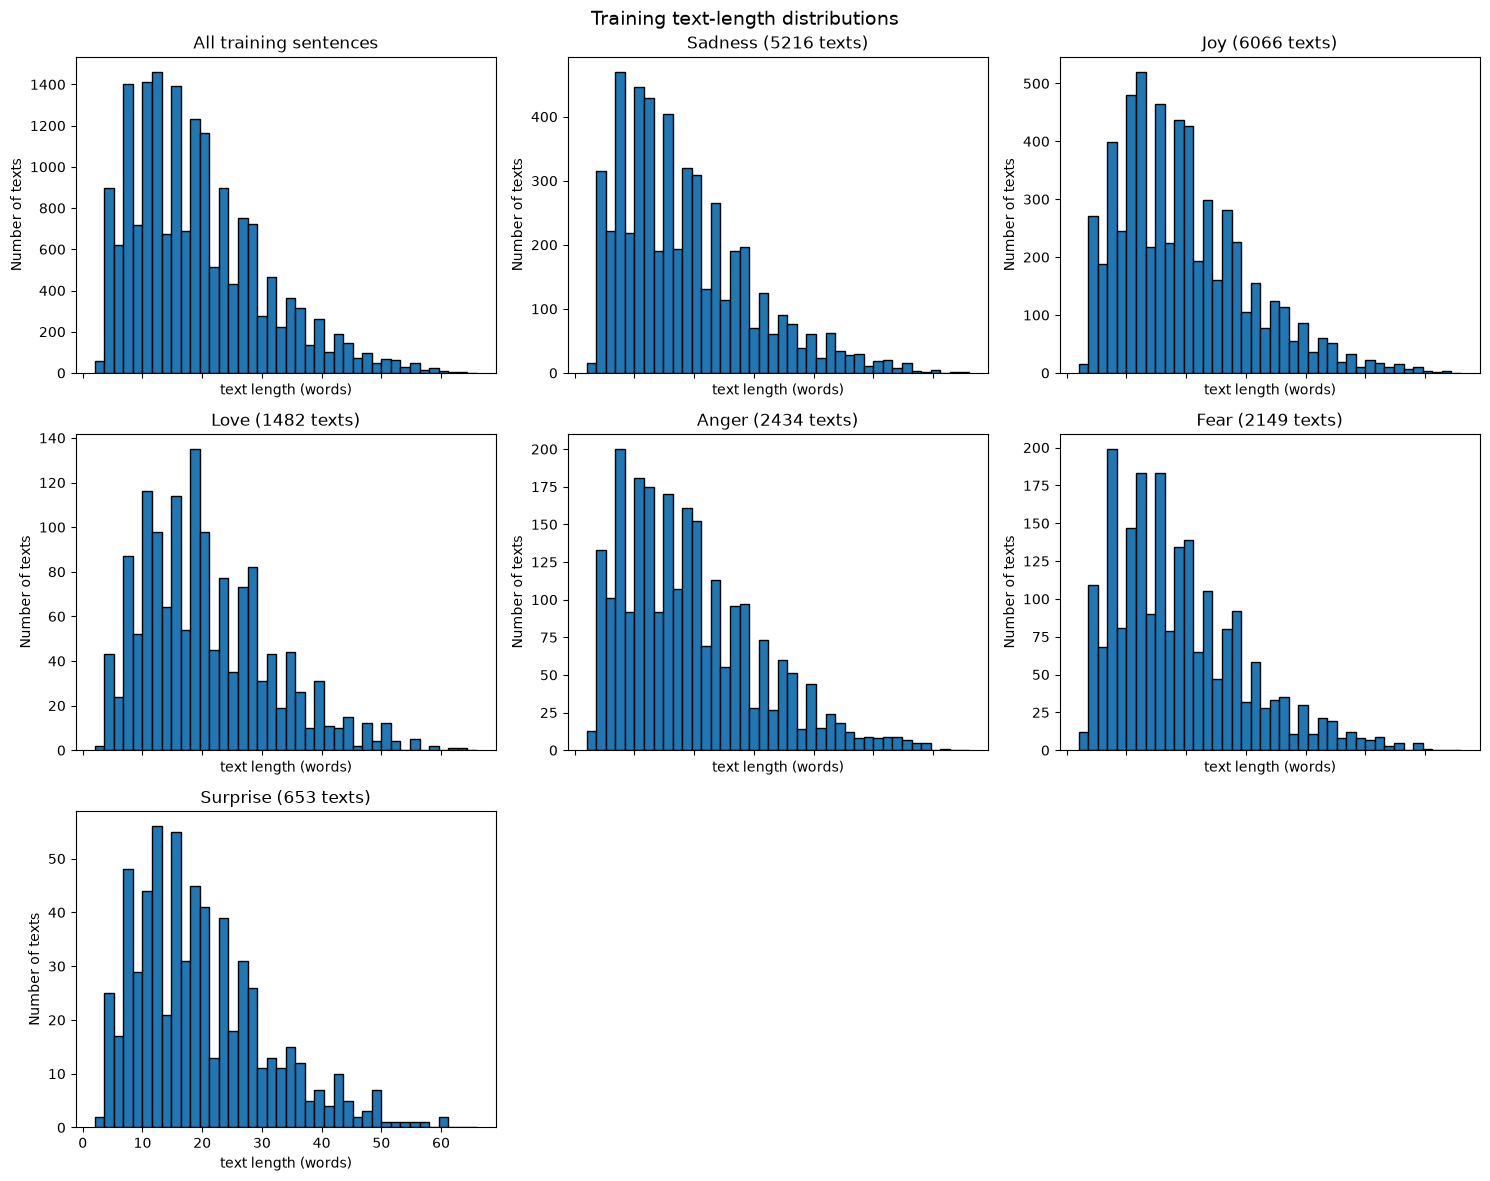

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import math

train_texts = dataset["train"]["text"]
labels = np.array(dataset["train"]["label"])

text_lengths = np.array([
    len(text.split())
    for text in train_texts
])

num_classes = len(outcome_space.names)
num_plots = num_classes + 1  # All data + one plot per class

ncols = 3
nrows = math.ceil(num_plots / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(5 * ncols, 4 * nrows),
    sharex=True,
)

axes = np.atleast_1d(axes).flatten()

# Use identical bins so the plots are directly comparable
bin_edges = np.histogram_bin_edges(text_lengths, bins=40)

# First plot: entire training set
axes[0].hist(
    text_lengths,
    bins=bin_edges,
    edgecolor="black",
)

axes[0].set_title("All training sentences")
axes[0].set_xlabel("text length (words)")
axes[0].set_ylabel("Number of texts")

# Remaining plots: one for each class
for label_id, label_name in enumerate(outcome_space.names):
    ax = axes[label_id + 1]
    class_lengths = text_lengths[labels == label_id]

    ax.hist(
        class_lengths,
        bins=bin_edges,
        edgecolor="black",
    )

    ax.set_title(f"{label_name.title()} ({len(class_lengths)} texts)")
    ax.set_xlabel("text length (words)")
    ax.set_ylabel("Number of texts")

# Hide unused subplot positions
for ax in axes[num_plots:]:
    ax.set_visible(False)

fig.suptitle(
    "Training text-length distributions",
    fontsize=14,
)

plt.tight_layout()
plt.show()

## Tokenizer

In [11]:
from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.trainers import WordLevelTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import Lowercase

corpus = dataset["train"]["text"]
choice = "word-level"

if choice == "bpe":
    vocab_size = 1000

    # min_frequency=2 means a pair must occur at least twice in the training corpus before it can be merged.
    min_frequency = 2

    tokenizer = part1.experiment.train_tokenizer(
        corpus,
        vocab_size,
        min_frequency
    )

if choice == "word-level":
    vocab_size = 1000
    min_frequency = 2
    unk_token = "??"
    
    # Create a word-level tokenizer that maps each known complete word
    # to one token ID.
    tokenizer = Tokenizer(WordLevel(unk_token=unk_token))
    
    # Convert text to lowercase during both training and later encoding.
    # This does not modify the original text strings.
    tokenizer.normalizer = Lowercase()

    # Split normalized text into words and punctuation before vocabulary lookup.
    tokenizer.pre_tokenizer = Whitespace()

    # Configure how the word-level vocabulary will be learned.
    trainer = WordLevelTrainer(
        vocab_size=vocab_size,
        min_frequency=min_frequency,
        special_tokens=[unk_token],
    )

    tokenizer.train_from_iterator(corpus, trainer=trainer)

text = corpus[0]
encoded = tokenizer.encode(text)

print("Original text:")
print(text)

print("\nWord-level tokens:")
print(encoded.tokens)

print("\nToken IDs:")
print(encoded.ids)

Original text:
i didnt feel humiliated

Word-level tokens:
['i', 'didnt', 'feel', 'humiliated']

Token IDs:
[1, 139, 2, 659]


In [12]:
tokenizer

Tokenizer(version="1.0", truncation=None, padding=None, added_tokens=[{"id":0, "content":"??", "single_word":False, "lstrip":False, "rstrip":False, "normalized":False, "special":True}], normalizer=Lowercase(), pre_tokenizer=Whitespace(), post_processor=None, decoder=None, model=WordLevel(vocab={"??":0, "i":1, "feel":2, "and":3, "to":4, "the":5, "a":6, "feeling":7, "that":8, "of":9, "my":10, "in":11, "it":12, "like":13, "so":14, "im":15, "for":16, "me":17, "was":18, "but":19, "have":20, "is":21, "am":22, "this":23, "with":24, "not":25, "about":26, "be":27, "as":28, "on":29, "you":30, "just":31, "when":32, "at":33, "or":34, "all":35, "because":36, "more":37, "do":38, "can":39, "really":40, "up":41, "t":42, "are":43, "by":44, "very":45, "know":46, "been":47, "if":48, "out":49, "myself":50, "time":51, "what":52, "how":53, "little":54, "get":55, "had":56, "will":57, "now":58, "from":59, "being":60, "they":61, "he":62, "people":63, "want":64, "would":65, "them":66, "her":67, "some":68, "stil

In [13]:
# TODO: We could possible apply data augmentation (Check DL lecture 4 slide 35/59)

## Representation spaces

### TokenIndicator

#### Tokenizer versus TokenIndicator: a simple example

Suppose the tokenizer vocabulary is `[[UNK], the, market, grows]`, with IDs `[0, 1, 2, 3]`. For the text `The market grows`, the tokenizer first lowercases the text, splits it into tokens, and returns an ordered sequence:

```text
Tokens:    [the, market, grows]
Token IDs: [1, 2, 3]
```

The `TokenIndicator` then converts those IDs into a fixed-size binary vector with one position per vocabulary token:

```text
Vocabulary:      [[UNK], the, market, grows]
Indicator vector: [  0,    1,      1,     1 ]
```

Thus, the **tokenizer** determines which tokens occur and returns their ordered IDs, whereas `TokenIndicator` records only whether each vocabulary token is present. It discards token order and frequency, so `market grows` and `grows market market` produce the same indicator vector.

In [14]:
class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")     

In [15]:
from tokenizers import Tokenizer
from sklearn.feature_extraction.text import TfidfVectorizer

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, text: str) -> np.ndarray:
        encoding = self.tokenizer.encode(text)
        unique_token_ids = np.unique(encoding.ids)

        vector = np.zeros(len(self), dtype=np.float32)
        vector[unique_token_ids] = 1.0

        return vector

class BagOfWords(Encoder):
    
    def __init__(self, tokenizer: Tokenizer):
            self.tokenizer = tokenizer

    def __len__(self) -> int:
            """Dimensionality of the representation space"""
            return len(self.tokenizer.get_vocab())
    
    def __call__(self, x: str) -> 'np.array':
            """Represent x as a D-dimensional vector of real numbers"""
            
            token_ids = self.tokenizer.encode(x).ids
            # A 0 vector with the same length as the vocabulary except in positions corresponding 
            # to tokens appearing in the document
            vector = np.bincount(
                        token_ids,
                        minlength=len(self),
                    ).astype(np.float32)
            return vector

class TfIdf(Encoder):

    def __init__(self, tokenizer: Tokenizer, corpus):
        self.tokenizer = tokenizer

        self.vectorizer = TfidfVectorizer(
            tokenizer=lambda text: self.tokenizer.encode(text).tokens,
            token_pattern=None,
            lowercase=False,
            vocabulary=self.tokenizer.get_vocab(),
        )

        self.vectorizer.fit(corpus)

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, text: str) -> np.ndarray:
        return (
            self.vectorizer
            .transform([text])
            .toarray()[0]
            .astype(np.float32)
        )

# Glove Word Embeddings https://www.geeksforgeeks.org/nlp/glove-word-embedding-in-nlp/
def embedding_for_vocab(filepath, word_index, embedding_dim):
    vocab_size = len(word_index) + 1  
    embedding_matrix_vocab = np.zeros((vocab_size, embedding_dim))

    with open(filepath, encoding="utf8") as f:
        for line in f:
            word, *vector = line.split()
            if word in word_index:
                idx = word_index[word]
                embedding_matrix_vocab[idx] = np.array(vector, dtype=np.float32)[:embedding_dim]

    return embedding_matrix_vocab


In [16]:
embedding_dim = 50 
glove_path = './glove/glove.6B.50d.txt'

embedding_matrix_vocab = embedding_for_vocab(glove_path, tokenizer.get_vocab(), embedding_dim)

In [17]:
embedding_matrix_vocab.shape

(1001, 50)

In [18]:
class GloveEncoder(Encoder):
    
    def __init__(self, tokenizer: Tokenizer):
            embedding_dim = 50 
            glove_path = './glove/glove.6B.300d.txt'            
            self.tokenizer = tokenizer
            self.embedding_matrix_vocab = embedding_for_vocab(glove_path, tokenizer.get_vocab(), embedding_dim)

    def __len__(self) -> int:
            """Dimensionality of the representation space"""
            return len(self.tokenizer.get_vocab())
    
    def __call__(self, x: str) -> 'np.array':
            """Represent x as a D-dimensional vector of real numbers"""
            
            token_ids = self.tokenizer.encode(x).ids
            # A 0 vector with the same length as the vocabulary except in positions corresponding 
            # to tokens appearing in the document
            token_embeddings = self.embedding_matrix_vocab[token_ids]
            return np.mean(token_embeddings, axis=0)


    
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer


class GloveTfidfEncoder(Encoder):

    def __init__(
        self,
        tokenizer: Tokenizer,
        corpus,
        glove_path="./glove/glove.6B.50d.txt",
        embedding_dim=50,
    ):
        self.tokenizer = tokenizer
        self.embedding_dim = embedding_dim

        self.embedding_matrix_vocab = embedding_for_vocab(
            glove_path,
            tokenizer.get_vocab(),
            embedding_dim,
        )

        self.vectorizer = TfidfVectorizer(
            tokenizer=lambda text: tokenizer.encode(text).tokens,
            token_pattern=None,
            lowercase=False,
            vocabulary=tokenizer.get_vocab(),
            sublinear_tf=True,
        )

        self.vectorizer.fit(corpus)

    def __len__(self) -> int:
        # The result is one embedding-sized sentence vector
        return self.embedding_dim

    def __call__(self, text: str) -> np.ndarray:
        tfidf_vector = self.vectorizer.transform([text])

        # IDs and TF-IDF weights of terms occurring in the text
        token_ids = tfidf_vector.indices
        weights = tfidf_vector.data.astype(np.float32)

        if token_ids.size == 0 or weights.sum() == 0:
            return np.zeros(
                self.embedding_dim,
                dtype=np.float32,
            )

        token_embeddings = self.embedding_matrix_vocab[token_ids]

        weighted_embedding = (
            token_embeddings * weights[:, None]
        ).sum(axis=0)

        return (
            weighted_embedding / weights.sum()
        ).astype(np.float32)
            
      

## Models

In [19]:
# Import smlp

## Training

In [20]:
## do the 3x3x2 training all models all encoders

In [21]:
print(dataset["train"][0]["text"])
print(type(dataset["train"][0]["text"]))

i didnt feel humiliated
<class 'str'>


In [22]:

# token_indicator_encoder = TfIdf(tokenizer, corpus)

# token_indicator_encoder = TfIdf(
#     tokenizer=tokenizer,
#     corpus=dataset["train"]["text"],
# )
# token_indicator_encoder = GloveEncoder(tokenizer=tokenizer)
# token_indicator_encoder = GloveTfidfEncoder(
#     tokenizer=tokenizer,
#     corpus=dataset["train"]["text"],
#     glove_path="./glove/glove.6B.300d.txt",
#     embedding_dim=300,
# )
token_indicator_encoder= BagOfWords(tokenizer)
vector = token_indicator_encoder(dataset["train"][0]["text"])


print(dataset["train"][0]["text"])

example = dataset["train"][0]["text"]
vector = token_indicator_encoder(example)

print(vector.shape)
print(vector.sum())


i didnt feel humiliated
(1000,)
4.0


In [23]:
%%time
my_seeds = [0, 3, 5] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

CPU times: user 403 ms, sys: 11.2 ms, total: 415 ms
Wall time: 416 ms


In [24]:
print(my_cross_validation_sets[0][0].keys())
print(len(my_cross_validation_sets))


dict_keys(['training', 'validation', 'training_ids', 'validation_ids'])
3


In [25]:
# %%time
# # train using the first fold (less than 1 min)
# # (don't mind the warning about convergence)

# logistic_model = part1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)  # remember to index datasets by [run][fold]

In [26]:
# %%time
# # for the model trained on the first fold (less than 10s)
# logistic_predictions = part1.loglin.predict([text for text, gold_label in my_cross_validation_sets[0][0]["validation"]], logistic_model, token_indicator_encoder)  # remember to index datasets by [run][fold]

In [27]:
# %%time
# from sklearn.metrics import accuracy_score

# # again, for the model trained on the first fold 
# logistic_accuracy = accuracy_score(
#     [gold_label for text, gold_label in my_cross_validation_sets[0][0]["validation"]],  # remember to index datasets by [run][fold]
#     logistic_predictions
# )
# print(f"Accuracy: {logistic_accuracy:.4f}")

### Cross Validation

In [28]:
from collections import OrderedDict

# save models and outputs there to keep the directory tree organised
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

PosixPath('results')

In [29]:
%%time
my_classifiers = OrderedDict()

my_classifiers['logistic_indicator-enc'] = []
#for token_enco in [bow, indicator, tfidf/bert embeddings]
#for model_dec in [logistic_regression, mlp1, mlp/w skip conn or dropout or svm]
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/project_logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 500
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

CPU times: user 1.06 s, sys: 11.7 ms, total: 1.07 s
Wall time: 1.08 s


KeyboardInterrupt: 

## Evaluation

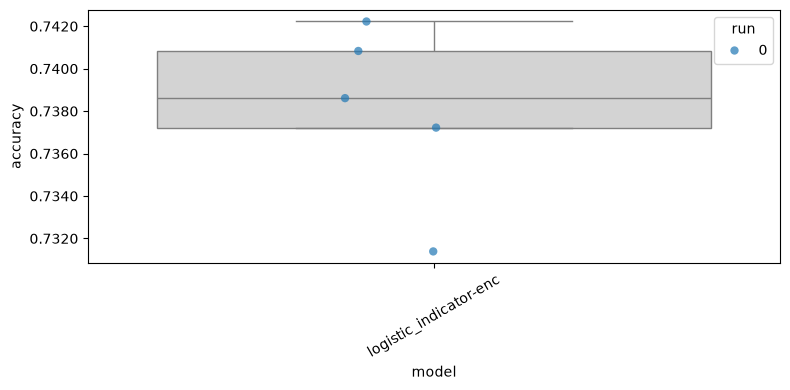

In [ ]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [ ]:
#TODO: visualise all possible combinations of enc-dec-features

In [54]:
%%time
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate([my_seeds]):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 30,
                'device': 'mps',
                'version': '2',
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 1.746 seconds
Dataloader done! Time taken: 0.055 seconds
Training...


  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3255 | train acc: 0.5067 | val loss: 0.7201 | val acc: 0.7692
Epoch 02 | train loss: 0.5214 | train acc: 0.8231 | val loss: 0.4544 | val acc: 0.8433
Epoch 03 | train loss: 0.3355 | train acc: 0.8840 | val loss: 0.4308 | val acc: 0.8406
Epoch 04 | train loss: 0.2571 | train acc: 0.9089 | val loss: 0.4475 | val acc: 0.8483
Epoch 05 | train loss: 0.2070 | train acc: 0.9295 | val loss: 0.4816 | val acc: 0.8372
Epoch 06 | train loss: 0.1629 | train acc: 0.9449 | val loss: 0.5083 | val acc: 0.8381
Epoch 07 | train loss: 0.1331 | train acc: 0.9547 | val loss: 0.5532 | val acc: 0.8383
Epoch 08 | train loss: 0.1076 | train acc: 0.9633 | val loss: 0.5891 | val acc: 0.8406
Epoch 09 | train loss: 0.0883 | train acc: 0.9710 | val loss: 0.6321 | val acc: 0.8444
Epoch 10 | train loss: 0.0746 | train acc: 0.9752 | val loss: 0.6796 | val acc: 0.8403
Epoch 11 | train loss: 0.0597 | train acc: 0.9820 | val loss: 0.7260 | val acc: 0.8339
Epoch 12 | train loss: 0.0555 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3163 | train acc: 0.5051 | val loss: 0.7640 | val acc: 0.7606
Epoch 02 | train loss: 0.5260 | train acc: 0.8222 | val loss: 0.4698 | val acc: 0.8397
Epoch 03 | train loss: 0.3243 | train acc: 0.8856 | val loss: 0.4501 | val acc: 0.8389
Epoch 04 | train loss: 0.2513 | train acc: 0.9090 | val loss: 0.4599 | val acc: 0.8431
Epoch 05 | train loss: 0.2001 | train acc: 0.9269 | val loss: 0.4980 | val acc: 0.8375
Epoch 06 | train loss: 0.1585 | train acc: 0.9435 | val loss: 0.5084 | val acc: 0.8414
Epoch 07 | train loss: 0.1309 | train acc: 0.9558 | val loss: 0.5531 | val acc: 0.8333
Epoch 08 | train loss: 0.1027 | train acc: 0.9659 | val loss: 0.5891 | val acc: 0.8331
Epoch 09 | train loss: 0.0852 | train acc: 0.9710 | val loss: 0.6357 | val acc: 0.8389
Epoch 10 | train loss: 0.0725 | train acc: 0.9755 | val loss: 0.6705 | val acc: 0.8358
Epoch 11 | train loss: 0.0623 | train acc: 0.9798 | val loss: 0.7099 | val acc: 0.8364
Epoch 12 | train loss: 0.0569 | train acc: 

... (2 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3151 | train acc: 0.5107 | val loss: 0.7347 | val acc: 0.7639
Epoch 02 | train loss: 0.5358 | train acc: 0.8212 | val loss: 0.4626 | val acc: 0.8431
Epoch 03 | train loss: 0.3492 | train acc: 0.8781 | val loss: 0.4322 | val acc: 0.8444
Epoch 04 | train loss: 0.2726 | train acc: 0.9022 | val loss: 0.4432 | val acc: 0.8397
Epoch 05 | train loss: 0.2252 | train acc: 0.9201 | val loss: 0.4583 | val acc: 0.8419
Epoch 06 | train loss: 0.1864 | train acc: 0.9340 | val loss: 0.4806 | val acc: 0.8411
Epoch 07 | train loss: 0.1498 | train acc: 0.9486 | val loss: 0.5219 | val acc: 0.8411
Epoch 08 | train loss: 0.1209 | train acc: 0.9582 | val loss: 0.5379 | val acc: 0.8389
Epoch 09 | train loss: 0.0999 | train acc: 0.9653 | val loss: 0.5848 | val acc: 0.8406
Epoch 10 | train loss: 0.0786 | train acc: 0.9749 | val loss: 0.6353 | val acc: 0.8425
Epoch 11 | train loss: 0.0710 | train acc: 0.9760 | val loss: 0.6785 | val acc: 0.8381
Epoch 12 | train loss: 0.0610 | train acc: 

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3272 | train acc: 0.4951 | val loss: 0.7495 | val acc: 0.7611
Epoch 02 | train loss: 0.5128 | train acc: 0.8240 | val loss: 0.4772 | val acc: 0.8331
Epoch 03 | train loss: 0.3305 | train acc: 0.8842 | val loss: 0.4555 | val acc: 0.8364
Epoch 04 | train loss: 0.2600 | train acc: 0.9061 | val loss: 0.4572 | val acc: 0.8425
Epoch 05 | train loss: 0.2078 | train acc: 0.9238 | val loss: 0.4784 | val acc: 0.8417
Epoch 06 | train loss: 0.1650 | train acc: 0.9437 | val loss: 0.5171 | val acc: 0.8478
Epoch 07 | train loss: 0.1353 | train acc: 0.9522 | val loss: 0.5646 | val acc: 0.8458
Epoch 08 | train loss: 0.1078 | train acc: 0.9635 | val loss: 0.5980 | val acc: 0.8414
Epoch 09 | train loss: 0.0879 | train acc: 0.9720 | val loss: 0.6388 | val acc: 0.8400
Epoch 10 | train loss: 0.0719 | train acc: 0.9773 | val loss: 0.7008 | val acc: 0.8378
Epoch 11 | train loss: 0.0667 | train acc: 0.9781 | val loss: 0.7028 | val acc: 0.8436
Epoch 12 | train loss: 0.0571 | train acc: 

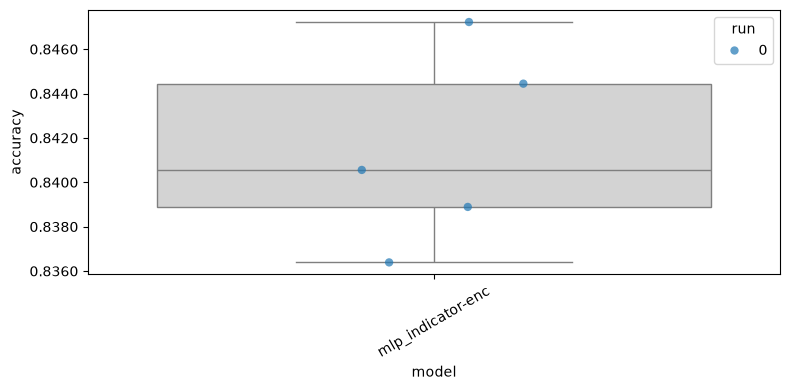

In [55]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))